In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imageio
from io import BytesIO

def sum_neighbours(matrix):
    # directions mean from where

    # direct neighbours
    up      = np.roll(matrix, 1, 0)
    down    = np.roll(matrix, -1, 0)
    left    = np.roll(matrix, 1, 1)
    right   = np.roll(matrix, -1, 1)

    # diagonals 
    up_left     = np.roll(up, 1, 1)
    up_right    = np.roll(up, -1, 1)
    down_left   = np.roll(down, 1, 1)
    down_right  = np.roll(down, -1, 1)

    neighbourhood_sum = up + down + left + right + up_left + up_right + down_left + down_right
    return neighbourhood_sum

def step(matrix, boundary_condition="wall"):
    neighbours = sum_neighbours(matrix)

    remains_1 = (neighbours == 2) & (matrix == 1)
    unconditional_1 = neighbours == 3
    final_mask = remains_1 | unconditional_1

    new_matrix = final_mask.astype(int)

    if boundary_condition == "wall":
        new_matrix[0, :] = 0
        new_matrix[-1, :] = 0
        new_matrix[:, 0] = 0
        new_matrix[:, -1] = 0

    return new_matrix

# Function to convert a matrix to an image
def matrix_to_image(mat):
    buf = BytesIO()
    plt.imshow(mat, cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.savefig(buf, format='png', bbox_inches='tight', pad_inches=0)
    plt.close()
    buf.seek(0)
    return imageio.v2.imread(buf)

def game_of_life_2D(matrix, time_steps, automata_name = "", make_gif = True, display_every=1, boundary_condition="wall"):

    #gif component
    if make_gif:
        frames = []
        # Initial state
        frames.append(matrix_to_image(matrix))

    print("Initial state:")
    plt.matshow(matrix, cmap="gray")
    plt.show()
    print(f"Showing state every {display_every} step/steps.")
    for i in range(time_steps-1):
        matrix = step(matrix, boundary_condition)
        if (i+1) % display_every == 0 and make_gif:
            frames.append(matrix_to_image(matrix))

    if make_gif:
        gif_name = "cellular_automata_"
        imageio.mimsave(gif_name+automata_name+".gif", frames, duration=0.2, loop=0)  # infinite loop
        print(f"GIF saved as {gif_name+automata_name}")

    print("Final state:")
    plt.matshow(matrix, cmap='gray')
    return matrix


In [2]:
if False:
    Matrix = np.zeros((11,11))
    Matrix[5,4] = 1
    Matrix[5,5] = 1
    # Matrix[5,6] = 1

    # Matrix[4,5] = 1

    game_of_life_2D(Matrix, 40, "death")

Initial state:


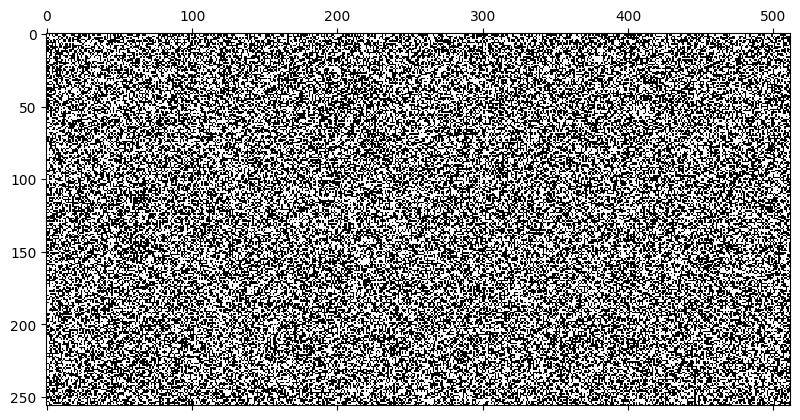

Showing state every 1 step/steps.
GIF saved as cellular_automata_
Final state:


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(256, 512))

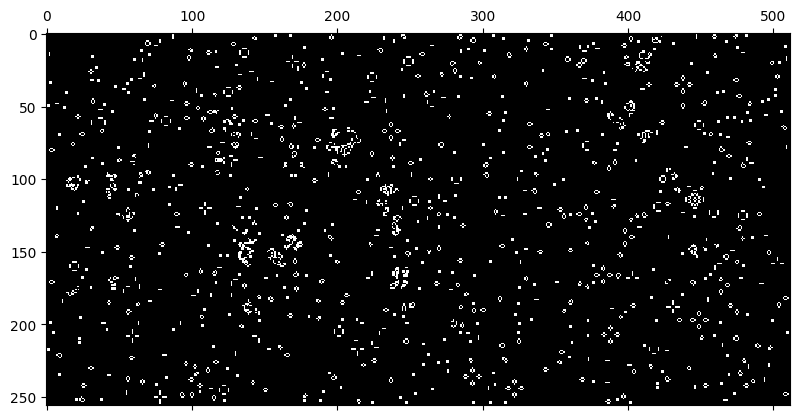

In [3]:
# task 1
Z = np.random.randint(0,2,(256,512))

game_of_life_2D(Z, 1000)

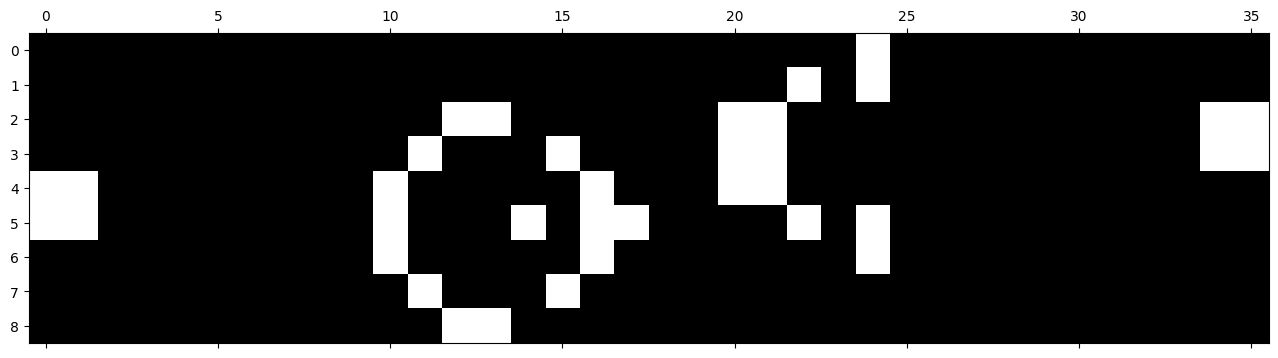

In [4]:
glider_gun = np.array(
[[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0],
[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0],
[0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1],
[0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1],
[1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0],
[1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0],
[0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0],
[0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],
[0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]]
)

plt.matshow(glider_gun, cmap='gray')

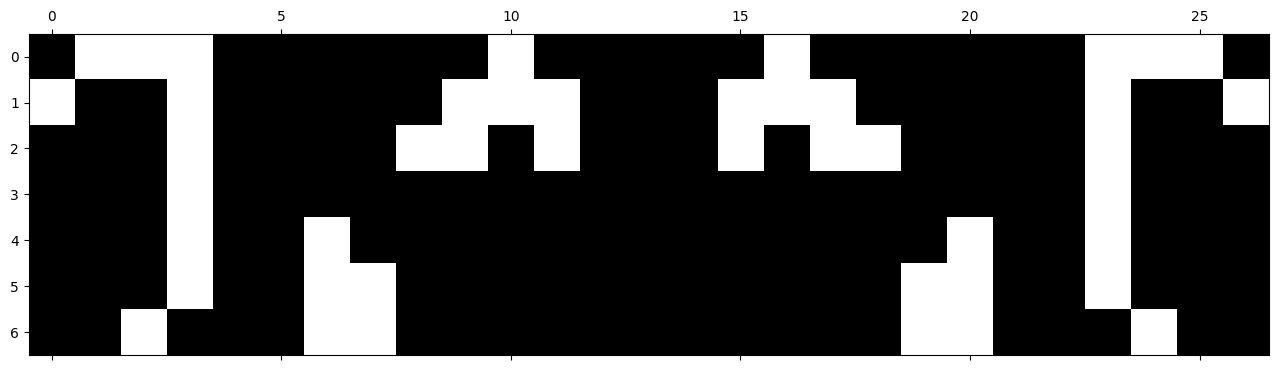

In [5]:
puffer = np.array(
[[0,1,1,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,1,1,0],
[1,0,0,1,0,0,0,0,0,1,1,1,0,0,0,1,1,1,0,0,0,0,0,1,0,0,1],
[0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,1,0,1,1,0,0,0,0,1,0,0,0],
[0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0],
[0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0],
[0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0],
[0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0]]
)
plt.matshow(puffer, cmap='gray')

In [6]:
# to import the different form into the numpy array we need to translate them from *'s and .'set
def text_to_array(pattern: str) -> np.ndarray:
    """
    Convert a Game of Life text pattern (string of '*' and '.') 
    into a 2D numpy array of 0s (dead) and 1s (alive).

    Example input:
    pattern = '''
    .*..
    **..
    ..*.
    '''
    """
    # Split into lines and remove empty lines / whitespace
    lines = [line.strip() for line in pattern.splitlines() if line.strip()]
    
    # Convert each line into a list of 0s and 1s
    array_data = []
    for line in lines:
        row = [1 if char == '*' else 0 for char in line]
        array_data.append(row)
    
    return np.array(array_data, dtype=int)

def embed_center(small: np.ndarray, big_shape: tuple) -> np.ndarray:
    """
    Embed a smaller matrix `small` into the center of a zero matrix of shape `big_shape`.
    
    Parameters:
        small: np.ndarray  -> the matrix to embed
        big_shape: tuple   -> shape of the target zero matrix (rows, cols)
    
    Returns:
        np.ndarray of shape `big_shape` with `small` centered
    """
    big = np.zeros(big_shape, dtype=small.dtype)
    
    # compute start indices
    start_row = (big_shape[0] - small.shape[0]) // 2
    start_col = (big_shape[1] - small.shape[1]) // 2
    
    # place the small matrix
    big[start_row:start_row + small.shape[0], start_col:start_col + small.shape[1]] = small
    
    return big


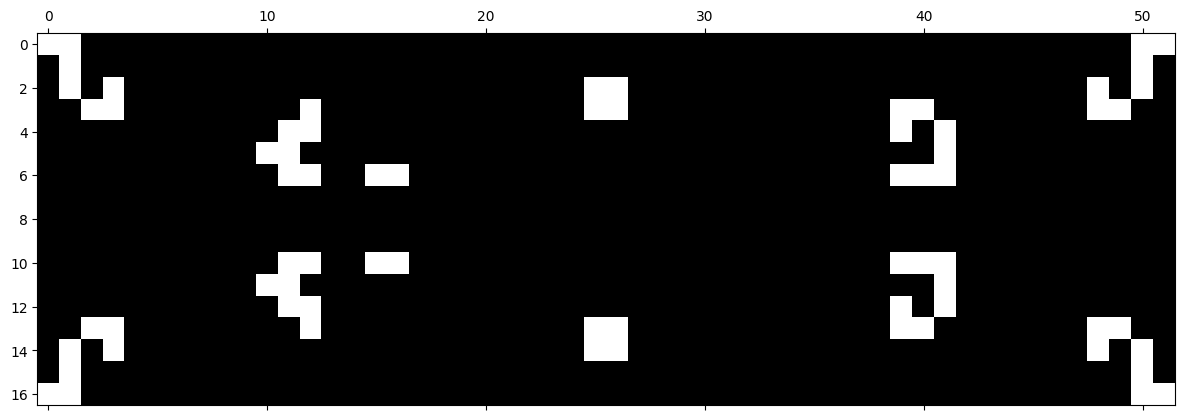

In [7]:
centinal = np.array(text_to_array(
"""
**................................................**
 .*................................................*.
 .*.*.....................**.....................*.*.
 ..**........*............**............**.......**..
 ...........**..........................*.*..........
 ..........**.............................*..........
 ...........**..**......................***..........
 ....................................................
 ....................................................
 ....................................................
 ...........**..**......................***..........
 ..........**.............................*..........
 ...........**..........................*.*..........
 ..**........*............**............**.......**..
 .*.*.....................**.....................*.*.
 .*................................................*.
 **................................................**
"""
))
plt.matshow(centinal, cmap='gray')

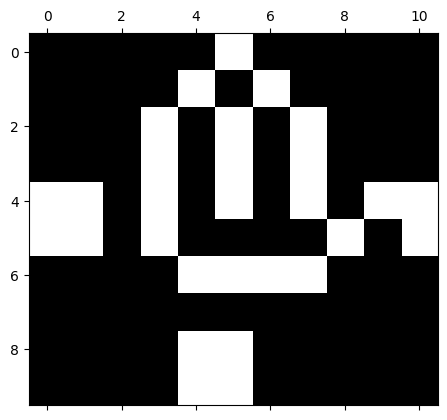

In [8]:
burloaferimeter = np.array(text_to_array(
"""
 .....*.....
 ....*.*....
 ...*.*.*...
 ...*.*.*...
 **.*.*.*.**
 **.*....*.*
 ....****...
 ...........
 ....**.....
 ....**.....
"""
))
plt.matshow(burloaferimeter, cmap='gray')

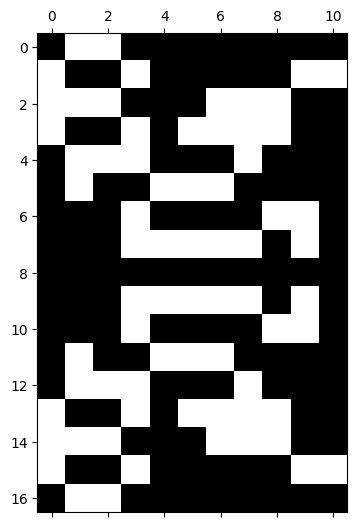

In [9]:
brain = np.array(text_to_array(
"""
.**........
 *..*.....**
 ***...***..
 *..*.****..
 .***...*...
 .*..***....
 ...*....**.
 ...*****.*.
 ...........
 ...*****.*.
 ...*....**.
 .*..***....
 .***...*...
 *..*.****..
 ***...***..
 *..*.....**
 .**........
"""
))
plt.matshow(brain, cmap='gray')

Initial state:


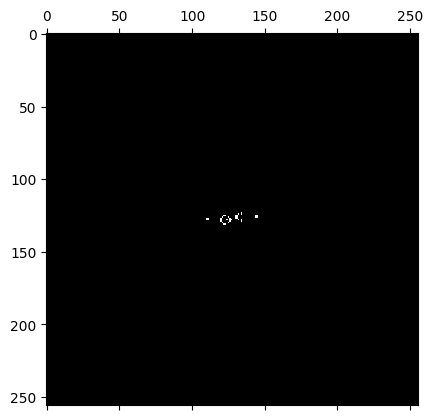

Showing state every 1 step/steps.
GIF saved as cellular_automata_glider_gun
Final state:


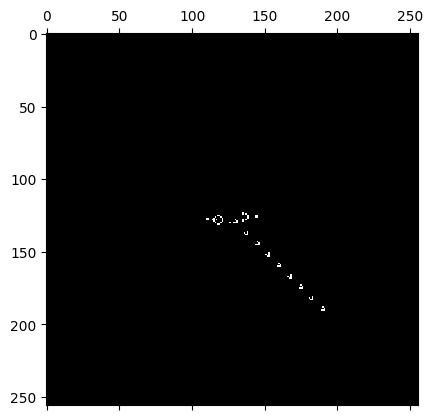

In [10]:
# Task 2 

def task_2(size, creature, time_steps, name):

    matrix = embed_center(creature, (size, size))
    game_of_life_2D(matrix, time_steps, name)

task_2(256, glider_gun, 256, "glider_gun")


Initial state:


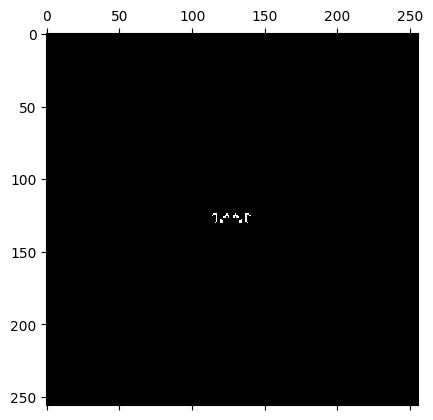

Showing state every 1 step/steps.
GIF saved as cellular_automata_puffer
Final state:


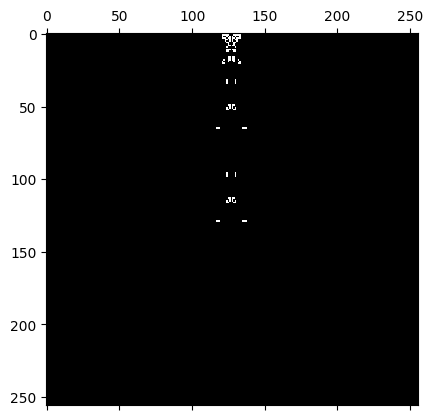

In [11]:
task_2(256, puffer, 256, "puffer")

Initial state:


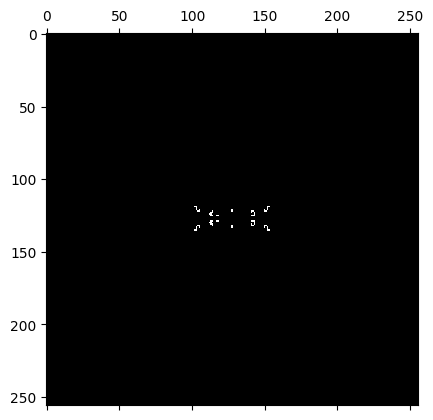

Showing state every 1 step/steps.
GIF saved as cellular_automata_centinal
Final state:


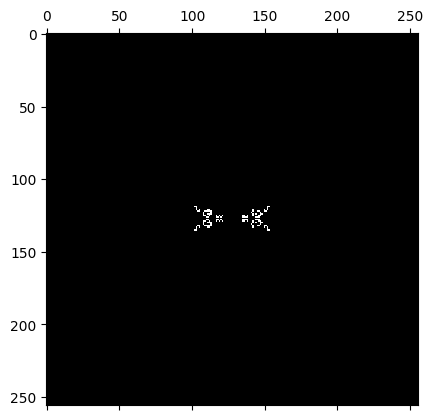

In [12]:
task_2(256, centinal, 256, "centinal")

Initial state:


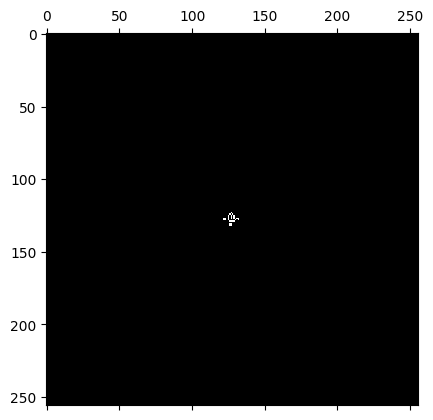

Showing state every 1 step/steps.
GIF saved as cellular_automata_burloaferimeter
Final state:


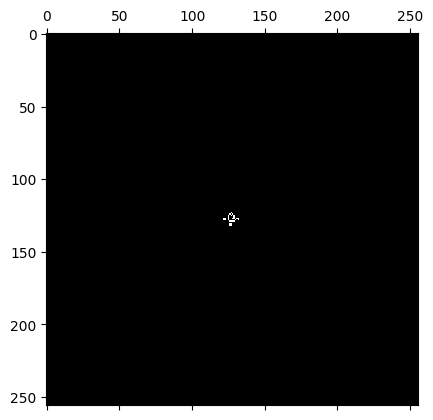

In [13]:
task_2(256, burloaferimeter, 256, "burloaferimeter")

Initial state:


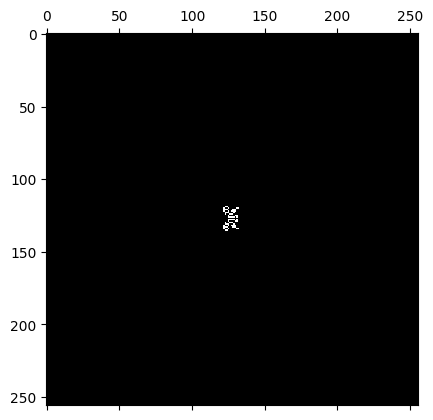

Showing state every 1 step/steps.
GIF saved as cellular_automata_brain
Final state:


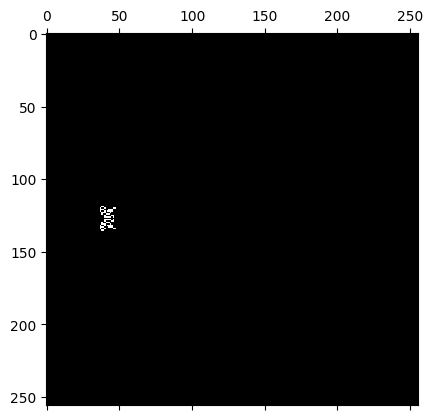

In [14]:
task_2(256, brain, 256, "brain")

Initial state:


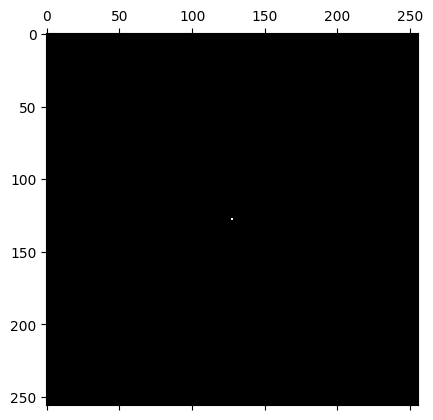

Showing state every 1 step/steps.
GIF saved as cellular_automata_beyond[]_[2 3 4]
Final state:


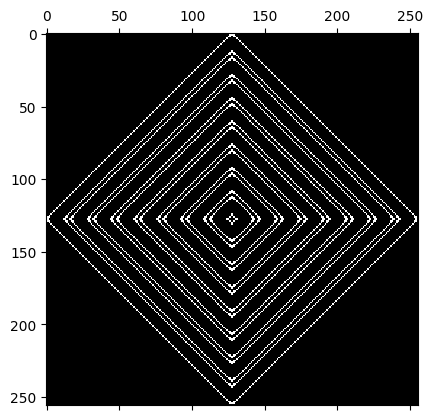

In [15]:
# task 3 beyond life

def step_defined(matrix, S, B, boundary_condition="wall"):
    # S - no. of live neighbors needed for a cell to survive
    # B - no. of live neighbors needed for a cell to be born
    neighbours = sum_neighbours(matrix)

    remains_1 = np.isin(neighbours, S) & (matrix == 1)
    unconditional_1 = np.isin(neighbours, B)
    final_mask = remains_1 | unconditional_1

    new_matrix = final_mask.astype(int)

    if boundary_condition == "wall":
        new_matrix[0, :] = 0
        new_matrix[-1, :] = 0
        new_matrix[:, 0] = 0
        new_matrix[:, -1] = 0

    return new_matrix

def game_of_life_2D_beyond(matrix, time_steps, S, B, make_gif = True, display_every=1, boundary_condition="wall"):
    automata_name = str(S) + "_" + str(B)

    #gif component
    if make_gif:
        frames = []
        # Initial state
        frames.append(matrix_to_image(matrix))

    print("Initial state:")
    plt.matshow(matrix, cmap="gray")
    plt.show()
    print(f"Showing state every {display_every} step/steps.")
    for i in range(time_steps-1):
        matrix = step_defined(matrix, S, B, boundary_condition)
        if (i+1) % display_every == 0 and make_gif:
            frames.append(matrix_to_image(matrix))

    if make_gif:
        gif_name = "cellular_automata_beyond"
        imageio.mimsave(gif_name+automata_name+".gif", frames, duration=0.2, loop=0)  # infinite loop
        print(f"GIF saved as {gif_name+automata_name}")

    print("Final state:")
    plt.matshow(matrix, cmap='gray')
    return matrix

def task_3(size, kernel, S, B, time_steps):
    matrix = embed_center(kernel, (size, size))
    B = np.array(B)
    S = np.array(S)
    game_of_life_2D_beyond(matrix, time_steps, S, B)

task_3(256, np.ones((2,2)), [], [2,3,4], 128)

Initial state:


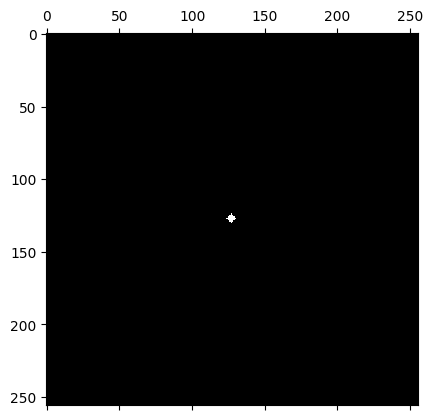

Showing state every 1 step/steps.
GIF saved as cellular_automata_beyond[0 1 2 3 4 5 6 7 8]_[3]
Final state:


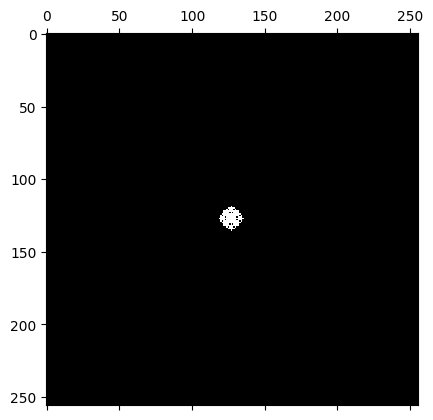

In [16]:
# Flakes
diamond = np.array([
[0,0,0,1,0,0,0],
[0,0,1,1,1,0,0],
[0,1,1,1,1,1,0],
[1,1,1,1,1,1,1],
[0,1,1,1,1,1,0],
[0,0,1,1,1,0,0],
[0,0,0,1,0,0,0]
])

task_3(256, diamond, [0,1,2,3,4,5,6,7,8], [3], 1024)

Initial state:


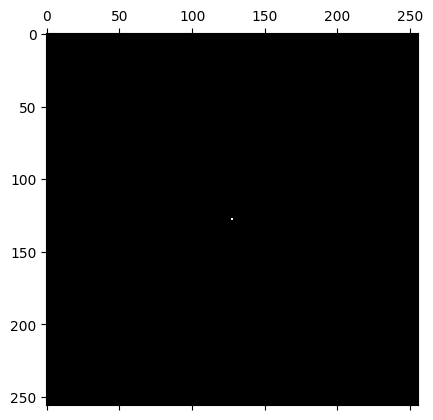

Showing state every 1 step/steps.
GIF saved as cellular_automata_beyond[1 2 3 4]_[3]
Final state:


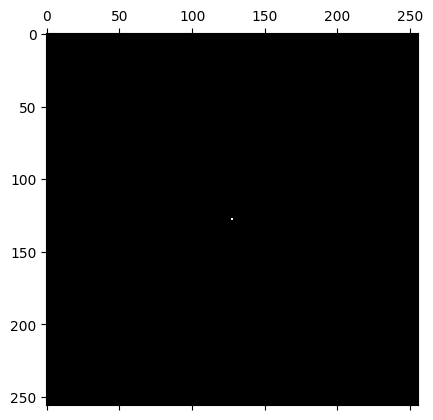

In [17]:
# Mazectric
task_3(256, np.ones((2,2)), [1,2,3,4], [3], 256)